# Stat 220, Unit 5 Homework: When a Line Is Not Enough

`rent.csv` is 4,743 rental listings from six Indian cities. `Rent` is the monthly
rent in rupees. The predictors are `Size` (square feet), `BHK` (bedrooms), `Bathroom`, `City`,
and `FurnishingStatus`. Rent runs from Rs 1,200 to Rs 3,500,000 a month.

Run the next two cells first. The first installs what you need, and the second loads the data
everything else uses.

In [ ]:
%pip install -q numpy pandas statsmodels scikit-learn matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

rent = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/rent.csv")
RHS = "BHK + Bathroom + C(City) + C(FurnishingStatus)"
rent.head()

**Problem 1.** *Is the line in trouble?* Fit rent on the predictors as they come.

Part a. Report the $R^2$ and the fan ratio, and paste the residual plot. The fan ratio is the spread of the residuals on the high half of the fitted values over the spread on the low half; 1 means even.

In [ ]:
plain = smf.ols(f"Rent ~ Size + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": plain.fittedvalues, "resid": plain.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(plain.rsquared, 3), "  fan ratio:", round(fan, 2))

plt.scatter(plain.fittedvalues, plain.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted rent"); plt.ylabel("residual");

The R^2 is 0.313, which explains about 31.3% of the variation, and the fan ratio is 4.90.

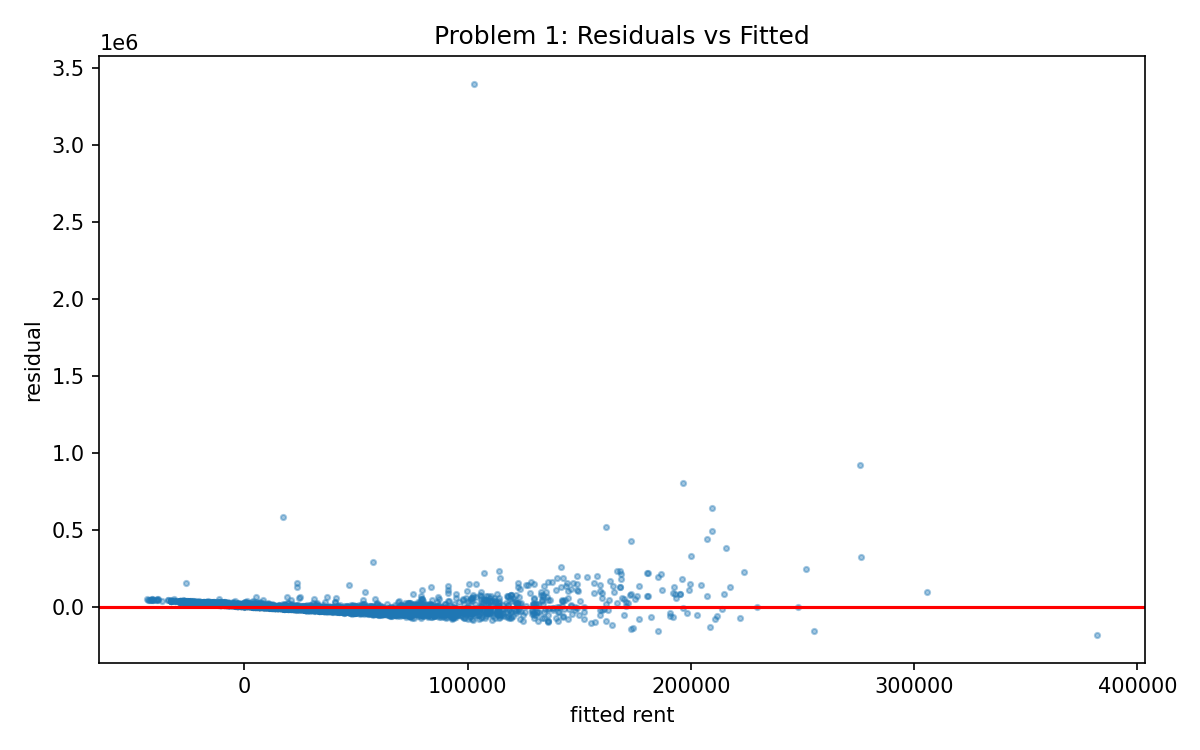

Part b. Name the two things wrong with this residual plot, and say what each one does to the predictions.

The residual plot has nonconstant variance, which makes predictions to have larger errors as they become more expensive so predication accuracy is less consistent across rent levels. Also, the residuals are a little nonlinear so the model may overpredict some rents and underpredict others.


**Problem 2.** *The fix.* Log both sides and look again.

Part a. Report the $R^2$ and the fan ratio for the logged model, next to the ones from problem 1.

In [ ]:
logged = smf.ols(f"np.log(Rent) ~ np.log(Size) + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": logged.fittedvalues, "resid": logged.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(logged.rsquared, 3), "  fan ratio:", round(fan, 2))
print("coefficient on log(Size):", round(logged.params["np.log(Size)"], 3))

plt.scatter(logged.fittedvalues, logged.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted log rent"); plt.ylabel("residual");

The R^2 is 0.770 and the fan ratio is 1.31.

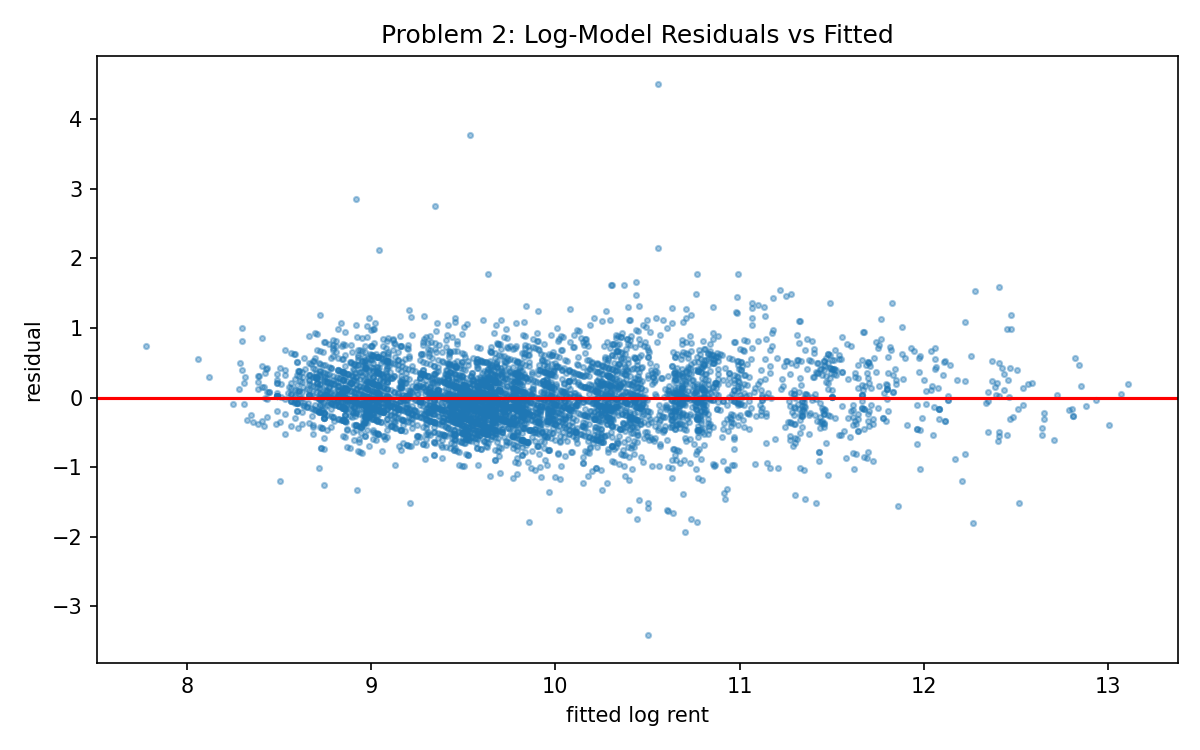

Part b. The coefficient on `np.log(Size)` is about 0.26. Write the sentence you would give a renter: what happens to the rent when the apartment is 10% bigger, with everything else the same?

The coefficient on log(Size) is approximately 0.26. Because both rent and size are log-transformed, this is an elasticity, which means a 1% increase in apartment size brings about approximately a 0.26% increase in rent. So, for a 10% increase in size the rent would increase by about 2.6%.


Part c. The $R^2$ went from problem 1's value to this one. Explain in two sentences why those two numbers cannot be compared directly.

The R^2 values cannot be directly compared because the first model predicts rent in rupees, while the second predicts log(rent). Since R^2 measures the variation explained in the outcome being predicted, the two values measure variation on different scales.

**Problem 3.** *A different idea.* Grow a shallow tree on the same columns and read it.

Part a. Print the tree and report its first three splits.

In [ ]:
X = pd.get_dummies(rent[["Size", "BHK", "Bathroom", "City", "FurnishingStatus"]],
                   drop_first=True)
y = np.log(rent.Rent)

tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X, y)
print(export_text(tree, feature_names=list(X.columns), decimals=2))

The first three splits are: Bathroom <=2.5 (the first split separates listings with 2 or fewer bathrooms from listings with 3 or more), City_Mumbai <=0.5 (among listings with 2 or fewer bathrooms, the tree separates listings outside Mumbai from listings in Mumbai), and Bathroom <=1.5 (among listings with 2 or fewer bathrooms that are outside Mumbai, the tree separates listings with 1 or fewer bathrooms from those with 2).


Part b. Describe the kind of listing that lands in the most expensive leaf, and the kind that lands in the cheapest.

Lowest predicted rent: listings outside Mumbai with 1 or fewer bathrooms. Highest predicted rent: listings in Mumbai with more than 2 bathrooms and a size greater than 1507 square feet.


Part c. The tree never splits on `FurnishingStatus`. Does that mean furnishing has no effect on rent? Explain.

Furnishing status was not selected by the decision tree, but that does not mean it has no relationship with rent. Other predictors may have provided more useful splits, or the tree's limited depth may have prevented furnishing status from being included.

**Problem 4.** *How deep should it go?*

Part a. Report the table, and say which depth you would use.

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)

for depth in [1, 2, 4, 6, 8, 10, 12]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, ytr)
    own = np.sqrt(((ytr - t.predict(Xtr))**2).mean())
    held = np.sqrt(((yte - t.predict(Xte))**2).mean())
    print(f"depth {depth:>2}   own rows {own:.3f}   held back {held:.3f}")

Because we want to predict rent for new listings the tree hasn't seen before, we want the lowest held-back error to judge how well it generalizes. So, we'd choose depth 6 because it has the lowest test error.


Part b. One column falls all the way down and the other turns around. Explain what each column is measuring and why only one of them can choose the depth.

The tree depth column measures our depth, the own rows column measures prediction error on the training data used to fit the tree, and held back measures prediction error on the test data that the tree did not use for training. Only held-back error can be used to choose the depth because we want the tree to generalize new listings and not just fit the training data.


**Problem 5.** *Let the tree inform the regression.* The tree splits on Mumbai, and then uses
a different `Size` cut inside the Mumbai branch than outside it.

Part a. Report the interaction coefficient, its p-value, and the AIC of both models.

In [ ]:
rent["mumbai"] = (rent.City == "Mumbai").astype(int)
inter = smf.ols(f"np.log(Rent) ~ np.log(Size) + np.log(Size):mumbai + {RHS}", data=rent).fit()

b = inter.params["np.log(Size)"]
extra = inter.params["np.log(Size):mumbai"]
print("elasticity outside Mumbai:", round(b, 3))
print("elasticity in Mumbai     :", round(b + extra, 3))
print("p-value on the interaction:", format(inter.pvalues["np.log(Size):mumbai"], ".2g"))
print("AIC:", round(logged.aic), "->", round(inter.aic))

The interaction coefficient is 0.255, the p-value is 1.53 x 10^-16, and the AIV before adding interaction is 5889 and after adding interaction is 5822.


Part b. Write three or four sentences a property manager could use. Give the number, the units, what is being held fixed, and what they should do about it.

The interaction coefficient is positive (0.255), meaning the relationship between apartment size and rent is stronger in Mumbai than in other cities. The estimated size elasticity is about 0.259 outside Mumbai and 0.513 in Mumbai, so a 1% increase in size is associated with about a 0.259% increase in rent outside Mumbai and a 0.513% increase in Mumbai.


Part c. A colleague says this proves that building bigger apartments in Mumbai causes higher rent per square foot. Explain why that is more than these listings can show, and say what they do show.

The interaction model is preferred because its AIC decreases from 5889 to 5822, indicating a better fit after accounting for model complexity. However, the relationship is an association, not necessarily a causal effect. Because the interaction was suggested after examining the data, it should also be evaluated on held-out data that was not used to discover the interaction.